# 4 · Did the models learn ripening or the season?

The only annotated run (series 1) lasted from 30 March to 2 August 2023. The sausages ripened in a traditional attic
without climate control, so **temperature rose together with the ripening phase**. A model can then reach a high score
by recognising "it is summer" instead of "the sausage is ripe". The score on series 1 cannot reveal this, because there
season and phase always go together.

The unannotated **series 2** (31 July 2023 to 3 April 2024: summer → winter → spring) can, even without labels:
ripening only moves forward, so the predicted phase must rise over time. A temperature-driven model predicts late
phases in August and falls back to early ones in winter.

**Using temperature without learning the season.** `temperature_difference` uses the probe temperatures *relative to the
air* (the seasonal level cancels out; a moist sausage stays cooler than the air through evaporation). The day/night swing
of the difference is still larger in summer, which `+temperature` addresses: per training window a random temperature
offset, scaled swings and mirrored swings.

**Augmentation against differences between sausages and probes** (training data only; `AUGMENTATIONS` in
`ml_core/augmentation.py`). Per-sausage scores range widely, so the models also depend on a sausage's own sensor levels.
* `+calibration_small` / `+calibration` / `+calibration_large` / `+calibration_xl`: per probe and day, moisture shifted
  (± 0.5 / 1 / 2 / 3 points) and conductivity scaled (± ~10 / 25 / 50 / 100 %), as if probes were calibrated or inserted
  differently. On 25 Nov 2026 the random forest gained with strength; `xl` checks where that stops. Too strong
  removes the signal itself (moisture differs by only a few points between the phases).
* `+robust`: measurement noise and 15 % lost uplinks, as in live operation. Aims at robustness in the case; here it
  can only show whether it costs accuracy.
Variants combine with `+`, e.g. `temperature_difference+calibration+robust`. Look at the **worst sausage** column, not
only the mean: calibration augmentation is meant to lift the weakest sausage.

**With long-term context** (default since 25 Nov 2026) the season can come back through the context: the 7-day spread of
the temperature difference is the day/night swing, larger in summer. `temperature_difference_now` keeps the
temperature difference of the current window but leaves out its 24 h / 7 d context (moisture and conductivity keep
theirs).

**A fourth model family:** `hgb` (histogram gradient boosting: trees added one after another, each correcting the
previous ones) is compared alongside the three demo models. Export it with `MODELS` in notebook 3 if it wins.

This notebook trains every model with each variant and compares
* **series 1, balanced accuracy**: leave-one-sausage-out, as in notebook 3 (mean, spread and worst sausage);
* **series 2, phase order ρ**: rank correlation of time and predicted phase (+1 = always advancing, negative = backwards);
* **series 2, backwards share**: share of time the predicted phase (smoothed over a week) lies below one reached earlier.

Caveat: series 2 may also ripen at a different pace (cold winter), so ρ says whether phases advance, not whether they are timed right.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root, so ml_core is importable
import matplotlib.pyplot as plt
import pandas as pd
from ml_core import data
from ml_core.training import (ALL_MODELS, DEFAULT_CONTEXT, DEFAULT_STRIDE, DEFAULT_WINDOW_SIZE, PROGRESSION_UNTIL,
                              compare_feature_sets, load_windows)
pd.set_option("display.width", 200)

In [2]:
CONVERTED_DIR = data.CONVERTED_DIR
WINDOW_SIZE, STRIDE, CONTEXT = DEFAULT_WINDOW_SIZE, DEFAULT_STRIDE, DEFAULT_CONTEXT   # notebook 05 compares these
# feature set, optionally "+augmentation+…" (names: AUGMENTATIONS in ml_core/augmentation.py). Each variant costs
# 3 models × 6 fits; augmented variants train on 3× the data.
VARIANTS = ["original", "no_temperature", "temperature_difference", "temperature_difference_now",
            "no_temperature+calibration_large", "temperature_difference+calibration_large",
            "temperature_difference_now+calibration_large", "temperature_difference_now+calibration_large+robust"]
MODELS = list(ALL_MODELS)           # incl. "hgb" (gradient boosting), the candidate 4th model
QUICK = False
N_JOBS = -1          # all fits (variants × models × folds) share one pool of worker processes

In [3]:
windows = load_windows(CONVERTED_DIR, window_size=WINDOW_SIZE, stride=STRIDE, context=CONTEXT)
unannotated = load_windows(CONVERTED_DIR, "series_2_*.csv", WINDOW_SIZE, STRIDE, annotated=False,
                           classes=windows.classes, context=CONTEXT)
pd.concat([windows.summary(), unannotated.summary()])[["recording", "windows", "from", "to"]]

series_1_sausage_1: 41,462 rows → 19,388 windows
series_1_sausage_2: 41,479 rows → 19,395 windows
series_1_sausage_3: 41,468 rows → 19,392 windows
series_1_sausage_4: 41,472 rows → 19,394 windows
series_1_sausage_5: 41,465 rows → 19,388 windows


series_2_sausage_1: 79,919 rows → 38,860 windows


series_2_sausage_2: 79,903 rows → 38,852 windows
series_2_sausage_3: 79,915 rows → 38,858 windows
series_2_sausage_4: 79,920 rows → 38,861 windows
series_2_sausage_5: 79,930 rows → 38,866 windows


,recording,windows,from,to
0,series_1_sausage_1,19388,2023-04-06 00:10:12.000000+00:00,2023-08-02 23:56:34.268438+00:00
1,series_1_sausage_2,19395,2023-04-06 00:11:14.000000+00:00,2023-08-02 23:43:26.013334+00:00
2,series_1_sausage_3,19392,2023-04-06 00:13:24.774014+00:00,2023-08-02 23:58:00.000000+00:00
3,series_1_sausage_4,19394,2023-04-06 00:05:37.000000+00:00,2023-08-02 23:55:25.481812+00:00
4,series_1_sausage_5,19388,2023-04-06 00:21:09.446387+00:00,2023-08-02 23:49:39.000000+00:00
0,series_2_sausage_1,38860,2023-08-07 22:06:14.000000+00:00,2024-04-03 06:49:51.257998+00:00
1,series_2_sausage_2,38852,2023-08-07 22:11:14.000000+00:00,2024-04-03 06:49:51.257998+00:00
2,series_2_sausage_3,38858,2023-08-07 22:18:00.000000+00:00,2024-04-03 06:50:28.017027+00:00
3,series_2_sausage_4,38861,2023-08-07 22:15:18.734759+00:00,2024-04-03 06:51:33.172636+00:00
4,series_2_sausage_5,38866,2023-08-07 22:09:39.000000+00:00,2024-04-03 06:49:51.257998+00:00


## Temperature over both runs: the confound in one picture (top), and what remains relative to the air (bottom)

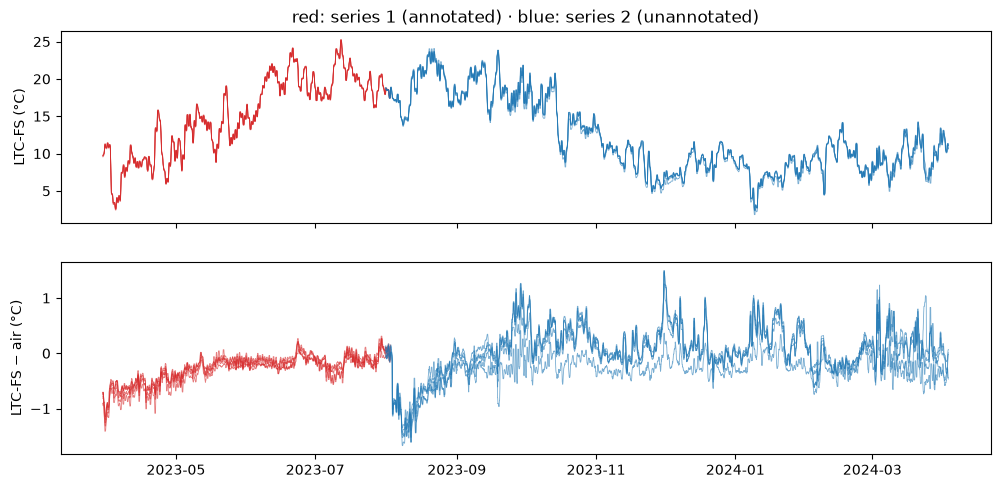

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for w, colour in ((windows, "tab:red"), (unannotated, "tab:blue")):
    for rec, raw in w.raw.items():
        t = raw[raw["sensor"] == "ltcfs"]
        ts = pd.to_datetime(t["timestamp"])
        axes[0].plot(ts, t["ltcfs_temperature"].rolling(50, min_periods=1).median(), color=colour, lw=.6, alpha=.6)
        axes[1].plot(ts, t["ltcfs_temperature_diff"].rolling(50, min_periods=1).median(), color=colour, lw=.6, alpha=.6)
axes[0].set(ylabel="LTC-FS (°C)", title="red: series 1 (annotated) · blue: series 2 (unannotated)")
axes[1].set(ylabel="LTC-FS − air (°C)")
plt.show()

In [5]:
table, progressions = compare_feature_sets(windows, unannotated, VARIANTS, keys=MODELS, quick=QUICK, n_jobs=N_JOBS)
table

Augmenting the training data (calibration_large): 2 copies per sausage …


Augmenting the training data (calibration_large + robust): 2 copies per sausage …


192 fits (8 variants × 4 models × folds) in parallel …


original · Logistic Regression: balanced acc 0.817 (folds 0.74, 0.81, 0.78, 0.85, 0.91)


original · Random Forest: balanced acc 0.860 (folds 0.74, 0.96, 0.86, 0.80, 0.95)


original · MLP (neural net): balanced acc 0.894 (folds 0.87, 0.89, 0.90, 0.92, 0.89)


... (23 outputs left out)

temperature_difference_now+calibration_large · MLP (neural net): balanced acc 0.745 (folds 0.67, 0.85, 0.76, 0.82, 0.63)
temperature_difference_now+calibration_large · Gradient Boosting: balanced acc 0.770 (folds 0.62, 0.89, 0.92, 0.80, 0.61)


temperature_difference_now+calibration_large+robust · Logistic Regression: balanced acc 0.790 (folds 0.67, 0.80, 0.76, 0.80, 0.92)
temperature_difference_now+calibration_large+robust · Random Forest: balanced acc 0.752 (folds 0.61, 0.61, 0.94, 0.81, 0.79)


temperature_difference_now+calibration_large+robust · MLP (neural net): balanced acc 0.708 (folds 0.66, 0.73, 0.77, 0.77, 0.61)
temperature_difference_now+calibration_large+robust · Gradient Boosting: balanced acc 0.710 (folds 0.34, 0.89, 0.90, 0.80, 0.62)


features  series 1: balanced acc  ± std  worst sausage  series 2: phase order ρ  series 2: backwards share
variant                                            model                                                                                                                          
original                                           Logistic Regression        53                   0.817  0.059          0.738                   -0.247                      0.478
                                                   Random Forest              53                   0.860  0.086          0.738                    0.144                      0.183
                                                   MLP (neural net)           53                   0.894  0.019          0.866                   -0.308                      0.224
                                                   Gradient Boosting          53                   0.855  0.136          0.602                   -0.611                      0.539
no_temperature                                     Logistic Regression        29                   0.782  0.070          0.670                    0.888                      0.064
                                                   Random Forest              29                   0.755  0.075          0.619                    0.890                      0.000
                                                   MLP (neural net)           29                   0.738  0.080          0.606                    0.808                      0.118
                                                   Gradient Boosting          29                   0.784  0.108          0.593                    0.802                      0.100
temperature_difference                             Logistic Regression        48                   0.801  0.069          0.705                    0.745                      0.147
                                                   Random Forest              48                   0.839  0.107          0.643                    0.831                      0.033
                                                   MLP (neural net)           48                   0.854  0.094          0.705                    0.633                      0.306
                                                   Gradient Boosting          48                   0.862  0.110          0.650                    0.808                      0.044
temperature_difference_now                         Logistic Regression        36                   0.768  0.050          0.694                    0.833                      0.090
                                                   Random Forest              36                   0.759  0.080          0.618                    0.832                      0.051
                                                   MLP (neural net)           36                   0.711  0.075          0.569                    0.803                      0.087
                                                   Gradient Boosting          36                   0.777  0.108          0.583                    0.772                      0.109
no_temperature+calibration_large                   Logistic Regression        29                   0.802  0.075          0.681                    0.897                      0.000
                                                   Random Forest              29                   0.754  0.105          0.610                    0.878                      0.003
                                                   MLP (neural net)           29                   0.730  0.034          0.674                    0.812                      0.105
                                                   Gradient Boosting          29                   0.752  0.126          0.610                    0.801                      0.028
temperature_difference+calibration_large           Logistic Regression        48                   0.831  0.072          0.758        

## Predicted phase on series 2 per feature set (smoothed over one day)

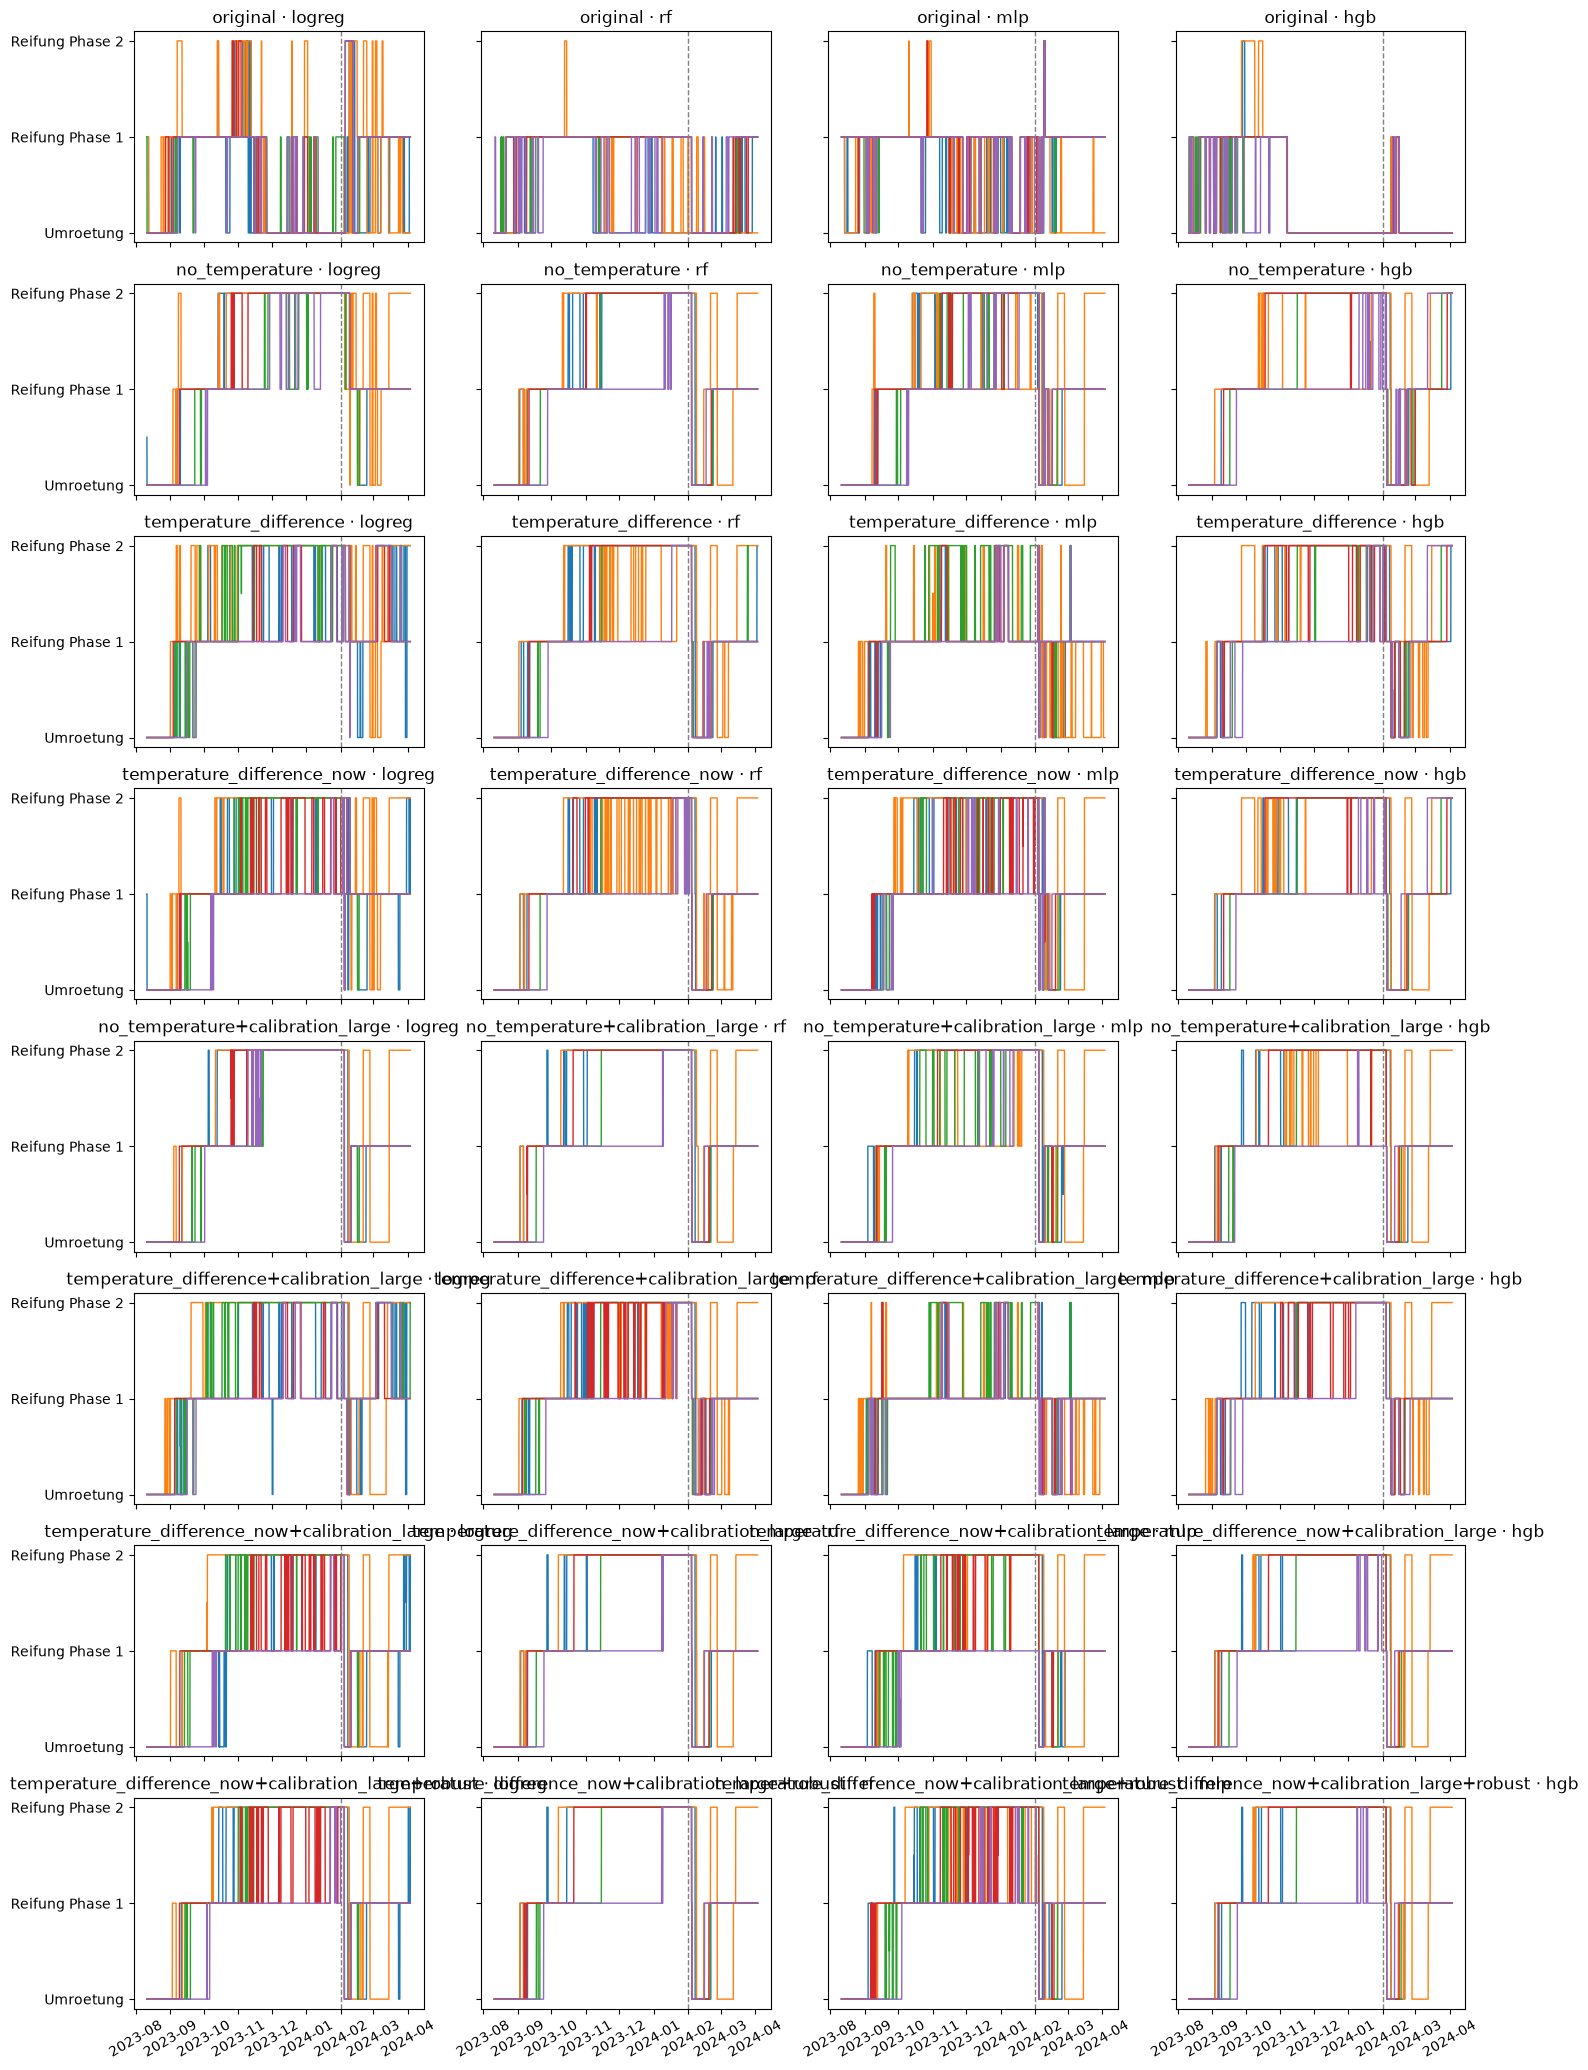

In [6]:
fsets = VARIANTS
keys = [k for k in MODELS if any(key == k for _, key in progressions)]
fig, axes = plt.subplots(len(fsets), len(keys), figsize=(15, 2.6 * len(fsets)), sharex=True, sharey=True, squeeze=False)
for i, fs in enumerate(fsets):
    for j, key in enumerate(keys):
        ax = axes[i][j]
        for rec, s in progressions[(fs, key)].items():
            ax.plot(s.index, s.values, lw=1)
        if PROGRESSION_UNTIL:
            ax.axvline(pd.Timestamp(PROGRESSION_UNTIL), color="grey", ls="--", lw=1)
        ax.set(title=f"{fs} · {key}", yticks=range(len(windows.classes)), yticklabels=windows.classes)
        ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

The dashed line marks `PROGRESSION_UNTIL`: from early February 2024 the LSE01 moisture of series 2 jumps from about 7 % to
22 % and all models fall back. The probes were probably moved or re-inserted (there is no log), so ρ and the backwards
share only score the time before it.

**How to read it:** a variant is only trustworthy if it scores well on series 1 *and* advances on series 2.
The default for notebooks 2 and 3 is `DEFAULT_FEATURE_SET` in `ml_core/training.py`; augmentation is switched on with
`AUGMENT = [...]` in notebook 3. Change them if the results favour another variant, then re-run notebooks 2 and 3.

**Limit:** the butcher annotated when the whole batch reached each phase, so the labels describe ripening, but in
series 1 ripening and the rising temperature happen together. Only the choice of inputs (the sausage's state, not the
season) decides which of the two a model learns, and series 2 is the only available check of that choice.